# Milestone 5 · Notebook 3: Configurations, Hyperparameters and Sweep Reliability

**Project:** Deepfake Voice Detection for Indian Languages · Group-3

This notebook answers the Milestone-4 review point on seed variation and multiple comparisons, and compares the configurations on the test sets:

1. **Holm correction** of the 24 sweep comparisons made on validation in Milestone 4: which decisions still hold.
2. **Seed spread** of the final config (F-01 to F-03) on the full test sets, against the clip-sampling intervals.
3. **Default vs final config** (D-01 vs F-01 to F-03) on the full test sets, with paired bootstrap intervals.
4. **Do validation choices transfer to test?** Every sweep checkpoint scored on the Milestone-4 test sample.

Inputs: `results/<run>/valid_predictions.csv` (Milestone 4), `results/<run>/predictions_full.csv.gz` (full test sets) and `results/<run>/predictions.csv` (sweeps on the test sample). No GPU is needed; it runs in about 10 minutes on a CPU.

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "Milestone-5" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.compare import holm, interval, p_value, paired_bootstrap
from src.metrics import eer

RESULTS = ROOT / "results"
FIGURES = ROOT / "assets" / "infographics" / "Milestone-5"
FIGURES.mkdir(parents=True, exist_ok=True)
TEST_SETS = {"test_indomain": "In-domain", "test_unseen_gen": "Unseen generators", "test_phone": "Phone channel",
             "test_itw": "In-the-Wild", "test_asvspoof": "ASVspoof eval"}
pd.set_option("display.width", 160)

## 1. Holm correction of the sweep comparisons

In Milestone 4 each sweep run was compared with its baseline on the same validation clips (paired bootstrap, 2,000 resamples), and a change counted if its 95% interval excluded zero. That is 24 tests at the 5% level, so about one false positive is expected by chance. Holm's step-down method controls the chance of *any* false positive across the 24 at 5%.

T-02 to T-14 are compared with T-01 (the default config); V-01 to V-11 with T-01c (the default config on the click-free data, Milestone 4 Section 2.4). The p-value is two-sided, from the bootstrap distribution; with 2,000 resamples the smallest possible value is 0.001.

In [2]:
CHANGES = {
    "T-02": "XLS-R lr 3e-6", "T-03": "XLS-R lr 3e-5", "T-04": "XLS-R lr 1e-4", "T-05": "Head lr 1e-4", "T-06": "Head lr 1e-2",
    "T-07": "2 s crops", "T-08": "6 s crops", "T-09": "Freeze 6 layers", "T-10": "Freeze 12 layers", "T-11": "Freeze 18 layers",
    "T-12": "Effective batch 16", "T-13": "Effective batch 32", "T-14": "Attentive pooling",
    "V-01": "Dropout 0.0", "V-02": "Dropout 0.3", "V-03": "Dropout 0.5", "V-04": "Weight decay 0.0", "V-05": "Weight decay 0.1",
    "V-06": "Noise + gain", "V-07": "Speed + pitch + reverb", "V-08": "RawBoost", "V-09": "Phone channel",
    "V-10": "All augmentations", "V-11": "No warmup, no clipping"}
ADOPTED = {"T-03", "V-03", "V-05", "V-09"}  # the changes in the final config

def valid_pair(run, base):
    a = pd.read_csv(RESULTS / base / "valid_predictions.csv")[["clip_id", "label", "p_fake"]]
    b = pd.read_csv(RESULTS / run / "valid_predictions.csv")[["clip_id", "p_fake"]]
    return a.merge(b, on="clip_id", suffixes=("_base", "_run"))

rows = []
for run, change in CHANGES.items():
    base = "T-01" if run.startswith("T") else "T-01c"
    m = valid_pair(run, base)
    diff, diffs = paired_bootstrap(m.label.eq("fake"), m.p_fake_base, m.p_fake_run, resamples=2000, seed=0)
    low, high = interval(diffs)
    rows.append({"run": run, "change": change, "baseline": base, "diff_pts": 100 * diff, "low": 100 * low,
                 "high": 100 * high, "p": p_value(diffs), "adopted": run in ADOPTED})
sweeps = pd.DataFrame(rows)
sweeps["p_holm"], sweeps["holm"] = holm(sweeps.p)
sweeps["uncorrected"] = (sweeps.high < 0) | (sweeps.low > 0)
sweeps.round(3)

,run,change,baseline,diff_pts,low,high,p,adopted,p_holm,holm,uncorrected
0,T-02,XLS-R lr 3e-6,T-01,3.029,2.297,3.585,0.001,False,0.024,True,True
1,T-03,XLS-R lr 3e-5,T-01,-0.782,-1.363,-0.530,0.001,True,0.024,True,True
2,T-04,XLS-R lr 1e-4,T-01,-0.883,-1.440,-0.580,0.001,False,0.024,True,True
3,T-05,Head lr 1e-4,T-01,0.303,-0.353,0.656,0.595,False,1.000,False,False
4,T-06,Head lr 1e-2,T-01,-0.354,-0.888,-0.104,0.008,False,0.088,False,True
5,T-07,2 s crops,T-01,1.010,0.202,1.413,0.008,False,0.088,False,True
6,T-08,6 s crops,T-01,-0.353,-0.883,-0.075,0.020,False,0.140,False,True
7,T-09,Freeze 6 layers,T-01,3.130,2.273,3.762,0.001,False,0.024,True,True
8,T-10,Freeze 12 layers,T-01,5.275,4.391,6.107,0.001,False,0.024,True,True
9,T-11,Freeze 18 layers,T-01,3.862,3.004,4.467,0.001,False,0.024,True,True


In [3]:
changed = sweeps[sweeps.uncorrected != sweeps.holm]
print(f"Significant before correction: {sweeps.uncorrected.sum()} of 24; after Holm: {sweeps.holm.sum()} of 24")
print("No longer significant after Holm:", ", ".join(f"{r.run} ({r.change}, {r.diff_pts:+.2f} pts, adjusted p {r.p_holm:.2f})"
                                               for r in changed.itertuples()))
print()
print(sweeps[sweeps.adopted][["run", "change", "diff_pts", "low", "high", "p_holm", "holm"]].round(3).to_string(index=False))

Significant before correction: 18 of 24; after Holm: 13 of 24
No longer significant after Holm: T-06 (Head lr 1e-2, -0.35 pts, adjusted p 0.09), T-07 (2 s crops, +1.01 pts, adjusted p 0.09), T-08 (6 s crops, -0.35 pts, adjusted p 0.14), V-02 (Dropout 0.3, -0.35 pts, adjusted p 0.10), V-05 (Weight decay 0.1, -0.46 pts, adjusted p 0.10)

 run           change  diff_pts    low   high  p_holm  holm
T-03    XLS-R lr 3e-5    -0.782 -1.363 -0.530   0.024  True
V-03      Dropout 0.5    -0.557 -0.935 -0.302   0.024  True
V-05 Weight decay 0.1    -0.455 -0.861 -0.102   0.099 False
V-09    Phone channel    -0.734 -1.165 -0.455   0.024  True


## 2. Seed spread of the final config on the full test sets

F-01, F-02 and F-03 are the same config trained with seeds 42, 43 and 44. For each test set: the EER of each seed with a 95% bootstrap interval over clips (1,000 resamples), and the spread across the three seeds. If the seeds differ by more than the clip intervals, the intervals understate how uncertain a single run is.

In [4]:
def full(run):
    p = pd.read_csv(RESULTS / run / "predictions_full.csv.gz")
    return p[p.split.isin(TEST_SETS)]

def eer_interval(part, resamples=1000, seed=0):
    y, s = part.label.eq("fake").to_numpy(int), part.p_fake.to_numpy()
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(resamples):
        idx = rng.integers(0, len(y), len(y))
        vals.append(eer(y[idx], s[idx])[0])
    return eer(y, s)[0], *np.percentile(vals, [2.5, 97.5])

final = {run: full(run) for run in ("F-01", "F-02", "F-03", "D-01")}
rows = []
for split, name in TEST_SETS.items():
    for run in ("F-01", "F-02", "F-03"):
        part = final[run][final[run].split == split]
        e, lo, hi = eer_interval(part)
        rows.append({"test_set": name, "run": run, "eer": 100 * e, "low": 100 * lo, "high": 100 * hi})
seeds = pd.DataFrame(rows)
spread = seeds.groupby("test_set", sort=False).agg(mean=("eer", "mean"), sd=("eer", "std"), lowest=("eer", "min"),
                                                  highest=("eer", "max"))
spread["seed_range"] = spread.highest - spread.lowest
spread["mean_clip_interval_width"] = (seeds.high - seeds.low).groupby(seeds.test_set, sort=False).mean()
display(seeds.round(2))
spread.round(2)

,test_set,run,eer,low,high
0,In-domain,F-01,0.02,0.00,0.10
1,In-domain,F-02,0.02,0.00,0.12
2,In-domain,F-03,0.00,0.00,0.00
3,Unseen generators,F-01,6.85,6.29,7.49
4,Unseen generators,F-02,9.73,9.08,10.44
5,Unseen generators,F-03,9.80,9.11,10.50
6,Phone channel,F-01,0.03,0.00,0.17
7,Phone channel,F-02,0.03,0.00,0.13
8,Phone channel,F-03,0.08,0.00,0.15
9,In-the-Wild,F-01,6.91,6.58,7.27


,mean,sd,lowest,highest,seed_range,mean_clip_interval_width
test_set,,,,,,
In-domain,0.01,0.01,0.00,0.02,0.02,0.07
Unseen generators,8.79,1.68,6.85,9.80,2.95,1.31
Phone channel,0.05,0.03,0.03,0.08,0.05,0.15
In-the-Wild,8.61,1.47,6.91,9.55,2.63,0.71
ASVspoof eval,9.99,5.49,5.42,16.08,10.66,0.53


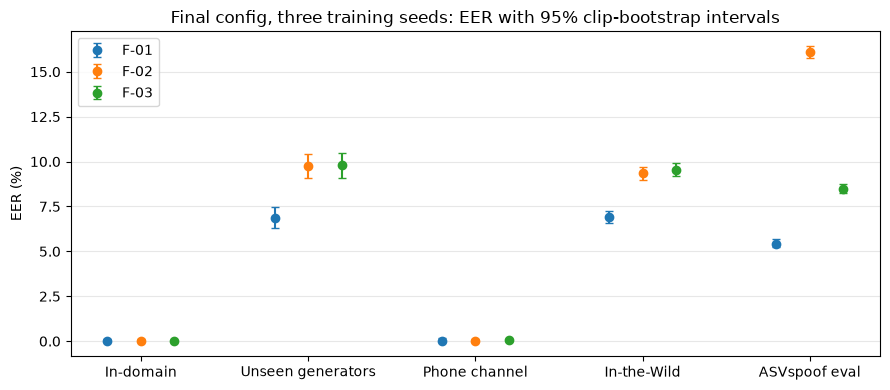

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = {"F-01": "#1f77b4", "F-02": "#ff7f0e", "F-03": "#2ca02c"}
for i, name in enumerate(TEST_SETS.values()):
    for j, run in enumerate(colors):
        r = seeds[(seeds.test_set == name) & (seeds.run == run)].iloc[0]
        ax.errorbar(i + (j - 1) * 0.2, r.eer, yerr=[[r.eer - r.low], [r.high - r.eer]], fmt="o", color=colors[run],
                    capsize=3, label=run if i == 0 else None)
ax.set_xticks(range(len(TEST_SETS)), TEST_SETS.values())
ax.set_ylabel("EER (%)")
ax.set_title("Final config, three training seeds: EER with 95% clip-bootstrap intervals")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "seed_spread.png", dpi=150)
plt.show()

## 3. Default config vs final config on the full test sets

D-01 (the untuned default config) against each final seed, paired on the same clips (1,000 resamples). Negative means the final seed has the lower EER.

In [6]:
rows = []
for split, name in TEST_SETS.items():
    d = final["D-01"][final["D-01"].split == split][["clip_id", "label", "p_fake"]]
    for run in ("F-01", "F-02", "F-03"):
        f = final[run][final[run].split == split][["clip_id", "p_fake"]]
        m = d.merge(f, on="clip_id", suffixes=("_d", "_f"))
        diff, diffs = paired_bootstrap(m.label.eq("fake"), m.p_fake_d, m.p_fake_f, resamples=1000, seed=0)
        low, high = interval(diffs)
        rows.append({"test_set": name, "run": run, "D-01": 100 * eer(m.label.eq("fake"), m.p_fake_d)[0],
                     "final": 100 * eer(m.label.eq("fake"), m.p_fake_f)[0], "diff_pts": 100 * diff,
                     "low": 100 * low, "high": 100 * high})
configs = pd.DataFrame(rows)
configs["verdict"] = np.where(configs.high < 0, "final better", np.where(configs.low > 0, "default better", "no clear difference"))
configs.round(2)

,test_set,run,D-01,final,diff_pts,low,high,verdict
0,In-domain,F-01,0.05,0.02,-0.03,-0.15,0.07,no clear difference
1,In-domain,F-02,0.05,0.02,-0.03,-0.12,0.02,no clear difference
2,In-domain,F-03,0.05,0.00,-0.05,-0.15,0.00,no clear difference
3,Unseen generators,F-01,6.85,6.85,0.00,-0.64,0.63,no clear difference
4,Unseen generators,F-02,6.85,9.73,2.88,2.14,3.57,default better
5,Unseen generators,F-03,6.85,9.80,2.95,2.15,3.72,default better
6,Phone channel,F-01,0.55,0.03,-0.52,-0.77,-0.32,final better
7,Phone channel,F-02,0.55,0.03,-0.52,-0.80,-0.32,final better
8,Phone channel,F-03,0.55,0.08,-0.47,-0.78,-0.32,final better
9,In-the-Wild,F-01,9.79,6.91,-2.87,-3.22,-2.55,final better


## 4. Do the validation choices transfer to test?

Every sweep checkpoint (T-01 to T-14, T-01c, V-01 to V-11) scored on `valid` and the Milestone-4 test sample (about 1,000 clips per test set), with the current (click-free) data.

The runs form two families. **T-01 to T-14 were trained before the click fix** (Milestone 4, Section 2.4), so they learnt from data where real clips carried the click and are now tested without it. **T-01c and V-01 to V-11 were trained on the click-free data.** Comparisons are made within a family only: the rank correlation between validation and test EER, and, for the adopted changes, the test EER difference against their own baseline. The validation EER is the one from training (Milestone 4), which is what the sweep decisions were based on.

In [7]:
from scipy.stats import spearmanr

SWEEPS = ["T-01", "T-01c"] + list(CHANGES)
have = [r for r in SWEEPS if (RESULTS / r / "results.json").exists()]
print(f"{len(have)} of {len(SWEEPS)} sweep runs scored on the test sample")
table = pd.DataFrame({r: json.load(open(RESULTS / r / "results.json"))["eer"] for r in have}).T * 100
table = table.drop(columns="valid").rename(columns=TEST_SETS)
table.insert(0, "Validation", [100 * json.load(open(RESULTS / r / "run.json"))["best_valid_eer"] for r in table.index])
table.insert(0, "family", ["before click fix" if r.startswith("T") and r != "T-01c" else "click-free" for r in table.index])
display(table.round(2))
corr = pd.DataFrame([{"family": fam, "test_set": name, **dict(zip(["spearman_rho", "p"], spearmanr(g["Validation"], g[name])))}
                     for fam, g in table.groupby("family") for name in TEST_SETS.values()])
corr.pivot(index="test_set", columns="family", values="spearman_rho").round(2)

26 of 26 sweep runs scored on the test sample


,family,Validation,In-domain,Unseen generators,Phone channel,In-the-Wild,ASVspoof eval
T-01,before click fix,1.08,0.0,12.7,3.0,19.11,11.49
T-01c,click-free,1.34,0.1,11.6,3.9,14.97,16.76
T-02,before click fix,4.11,0.9,16.0,7.5,24.84,18.76
T-03,before click fix,0.30,0.0,7.5,1.4,13.48,7.38
T-04,before click fix,0.20,0.0,7.3,2.9,9.55,6.53
T-05,before click fix,1.39,0.0,10.4,2.6,17.51,12.01
T-06,before click fix,0.68,0.1,24.6,12.4,17.82,10.99
T-07,before click fix,1.97,0.1,17.3,3.6,18.35,14.22
T-08,before click fix,0.76,0.0,12.1,1.7,15.39,8.43
T-09,before click fix,4.32,0.6,18.1,4.2,26.12,15.80


family,before click fix,click-free
test_set,,
ASVspoof eval,0.93,0.87
In-domain,0.83,0.33
In-the-Wild,0.92,0.68
Phone channel,0.61,0.90
Unseen generators,0.67,0.46


In [8]:
rows = []
for run in sorted(ADOPTED):
    base = "T-01" if run.startswith("T") else "T-01c"
    if run not in table.index:
        continue
    for name in ["Validation", *TEST_SETS.values()]:
        rows.append({"run": run, "change": CHANGES[run], "set": name,
                     "diff_pts": table.loc[run, name] - table.loc[base, name]})
transfer = pd.DataFrame(rows).pivot(index=["run", "change"], columns="set", values="diff_pts")[["Validation", *TEST_SETS.values()]]
transfer.round(2)

,set,Validation,In-domain,Unseen generators,Phone channel,In-the-Wild,ASVspoof eval
run,change,,,,,,
T-03,XLS-R lr 3e-5,-0.78,0.0,-5.2,-1.6,-5.63,-4.11
V-03,Dropout 0.5,-0.61,0.2,-0.8,-2.8,-4.35,-4.64
V-05,Weight decay 0.1,-0.43,0.1,-1.6,-1.9,-1.80,-2.85
V-09,Phone channel,-0.73,-0.1,3.0,-3.9,-0.43,-5.06


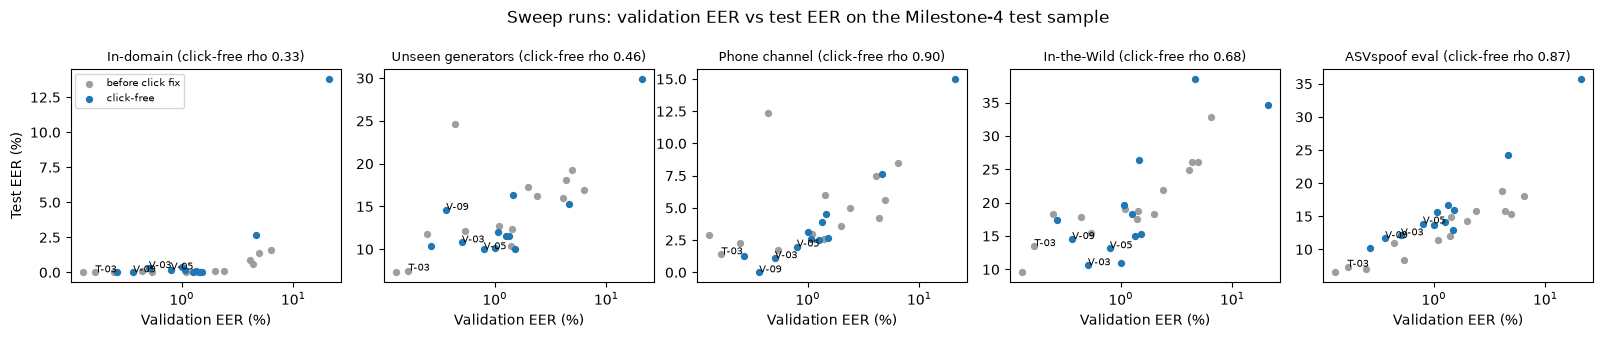

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4), sharex=True)
for ax, name in zip(axes, TEST_SETS.values()):
    for fam, color in (("before click fix", "#9e9e9e"), ("click-free", "#1f77b4")):
        g = table[table.family == fam]
        ax.scatter(g["Validation"], g[name], s=18, color=color, label=fam)
    for run in ADOPTED & set(table.index):
        ax.annotate(run, (table.loc[run, "Validation"], table.loc[run, name]), fontsize=7)
    ax.set_xscale("symlog", linthresh=1)
    rho = corr[(corr.test_set == name) & (corr.family == "click-free")].spearman_rho.iloc[0]
    ax.set_title(f"{name} (click-free rho {rho:.2f})", fontsize=9)
    ax.set_xlabel("Validation EER (%)")
axes[0].set_ylabel("Test EER (%)")
axes[0].legend(fontsize=7)
fig.suptitle("Sweep runs: validation EER vs test EER on the Milestone-4 test sample")
fig.tight_layout()
fig.savefig(FIGURES / "sweep_transfer.png", dpi=150)
plt.show()

## 5. Summary

The numbers for the report section are printed below; the interpretation is in `milestones/Milestone-5/Milestone-5.md`.

In [10]:
print("Holm:", sweeps.uncorrected.sum(), "->", sweeps.holm.sum(), "significant of 24")
print("Adopted changes surviving Holm:", ", ".join(sweeps[sweeps.adopted & sweeps.holm].change))
print("Adopted changes not surviving:", ", ".join(sweeps[sweeps.adopted & ~sweeps.holm].change))
print()
print("Seed spread (EER %, F-01..F-03):")
for name, r in spread.iterrows():
    print(f"  {name:18s} {r.lowest:5.2f} to {r.highest:5.2f}  (range {r.seed_range:.2f} pts; mean clip interval width {r.mean_clip_interval_width:.2f} pts)")
print()
print(configs.groupby("test_set", sort=False).verdict.agg(lambda v: ", ".join(v)))

Holm: 18 -> 13 significant of 24
Adopted changes surviving Holm: XLS-R lr 3e-5, Dropout 0.5, Phone channel
Adopted changes not surviving: Weight decay 0.1

Seed spread (EER %, F-01..F-03):
  In-domain           0.00 to  0.02  (range 0.02 pts; mean clip interval width 0.07 pts)
  Unseen generators   6.85 to  9.80  (range 2.95 pts; mean clip interval width 1.31 pts)
  Phone channel       0.03 to  0.08  (range 0.05 pts; mean clip interval width 0.15 pts)
  In-the-Wild         6.91 to  9.55  (range 2.63 pts; mean clip interval width 0.71 pts)
  ASVspoof eval       5.42 to 16.08  (range 10.66 pts; mean clip interval width 0.53 pts)

test_set
In-domain            no clear difference, no clear difference, no c...
Unseen generators    no clear difference, default better, default b...
Phone channel                 final better, final better, final better
In-the-Wild            final better, final better, no clear difference
ASVspoof eval               final better, default better, final better
